# Projet 4 : Classifiez automatiquement des informations

## Analyse exploratoire des données (EDA)

### 1 - Chargement des librairies et du fichier

In [13]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sb
import numpy as np

In [ ]:
DATA_RAW = Path("../Data/Raw")

df_brut_sirh = pd.read_csv(DATA_RAW / "extrait_sirh.csv")

### 2 - Audit du dataset

dataset complet

In [4]:
df_brut_sirh

,id_employee,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,nombre_heures_travailless,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel
0,1,41,F,5993,Célibataire,Commercial,Cadre Commercial,8,80,8,6,4
1,2,49,M,5130,Marié(e),Consulting,Assistant de Direction,1,80,10,10,7
2,4,37,M,2090,Célibataire,Consulting,Consultant,6,80,7,0,0
3,5,33,F,2909,Marié(e),Consulting,Assistant de Direction,1,80,8,8,7
4,7,27,M,3468,Marié(e),Consulting,Consultant,9,80,6,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...
1465,2061,36,M,2571,Marié(e),Consulting,Consultant,4,80,17,5,2
1466,2062,39,M,9991,Marié(e),Consulting,Manager,4,80,9,7,7
1467,2064,27,M,6142,Marié(e),Consulting,Tech Lead,1,80,6,6,2
1468,2065,49,M,5390,Marié(e),Commercial,Cadre Commercial,2,80,17,9,6


Dimensions du dataset

In [5]:
df_brut_sirh.shape

(1470, 12)

Nulls, et types de colonnes

In [6]:
df_brut_sirh.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 12 columns):
 #   Column                          Non-Null Count  Dtype 
---  ------                          --------------  ----- 
 0   id_employee                     1470 non-null   int64 
 1   age                             1470 non-null   int64 
 2   genre                           1470 non-null   object
 3   revenu_mensuel                  1470 non-null   int64 
 4   statut_marital                  1470 non-null   object
 5   departement                     1470 non-null   object
 6   poste                           1470 non-null   object
 7   nombre_experiences_precedentes  1470 non-null   int64 
 8   nombre_heures_travailless       1470 non-null   int64 
 9   annee_experience_totale         1470 non-null   int64 
 10  annees_dans_l_entreprise        1470 non-null   int64 
 11  annees_dans_le_poste_actuel     1470 non-null   int64 
dtypes: int64(8), object(4)
memory usage: 137.9+ KB


Min, Max

In [7]:
df_brut_sirh.describe(include='all')

,id_employee,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,nombre_heures_travailless,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel
count,1470.000000,1470.000000,1470,1470.000000,1470,1470,1470,1470.000000,1470.0,1470.000000,1470.000000,1470.000000
unique,NaN,NaN,2,NaN,3,3,9,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,M,NaN,Marié(e),Consulting,Cadre Commercial,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,882,NaN,673,961,326,NaN,NaN,NaN,NaN,NaN
mean,1024.865306,36.923810,NaN,6502.931293,NaN,NaN,NaN,2.693197,80.0,11.279592,7.008163,4.229252
std,602.024335,9.135373,NaN,4707.956783,NaN,NaN,NaN,2.498009,0.0,7.780782,6.126525,3.623137
min,1.000000,18.000000,NaN,1009.000000,NaN,NaN,NaN,0.000000,80.0,0.000000,0.000000,0.000000
25%,491.250000,30.000000,NaN,2911.000000,NaN,NaN,NaN,1.000000,80.0,6.000000,3.000000,2.000000
50%,1020.500000,36.000000,NaN,4919.000000,NaN,NaN,NaN,2.000000,80.0,10.000000,5.000000,3.000000
75%,1555.750000,43.000000,NaN,8379.000000,NaN,NaN,NaN,4.000000,80.0,15.000000,9.000000,7.000000


Doubons sur tout le dataset

In [8]:
df_brut_sirh.duplicated().value_counts()

False    1470
Name: count, dtype: int64

Doublons sur la colonne identifiante 

In [9]:
df_brut_sirh.duplicated(subset=['id_employee']).value_counts()

False    1470
Name: count, dtype: int64

### 3 - Exploration des données

In [10]:
df_brut_sirh

,id_employee,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,nombre_heures_travailless,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel
0,1,41,F,5993,Célibataire,Commercial,Cadre Commercial,8,80,8,6,4
1,2,49,M,5130,Marié(e),Consulting,Assistant de Direction,1,80,10,10,7
2,4,37,M,2090,Célibataire,Consulting,Consultant,6,80,7,0,0
3,5,33,F,2909,Marié(e),Consulting,Assistant de Direction,1,80,8,8,7
4,7,27,M,3468,Marié(e),Consulting,Consultant,9,80,6,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...
1465,2061,36,M,2571,Marié(e),Consulting,Consultant,4,80,17,5,2
1466,2062,39,M,9991,Marié(e),Consulting,Manager,4,80,9,7,7
1467,2064,27,M,6142,Marié(e),Consulting,Tech Lead,1,80,6,6,2
1468,2065,49,M,5390,Marié(e),Commercial,Cadre Commercial,2,80,17,9,6


Proportion par sexe des employés

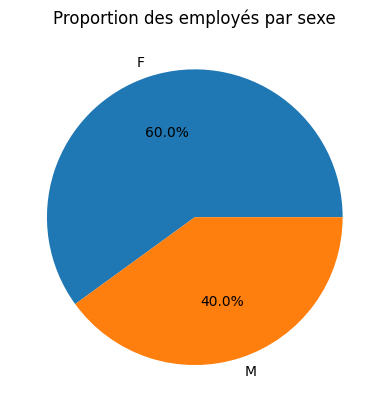

In [14]:
plt.pie(df_brut_sirh['genre'].value_counts(),labels=df_brut_sirh['genre'].unique(), autopct="%1.1f%%")
plt.title('Proportion des employés par sexe')
plt.show()

Proportion par situation matrinoniale (situation marital) des employés

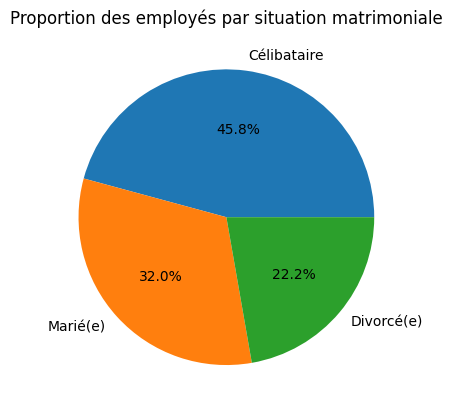

In [15]:
plt.pie(df_brut_sirh['statut_marital'].value_counts(),labels=df_brut_sirh['statut_marital'].unique(), autopct="%1.1f%%")
plt.title('Proportion des employés par situation matrimoniale')
plt.show()

Proportion des employés par type de poste

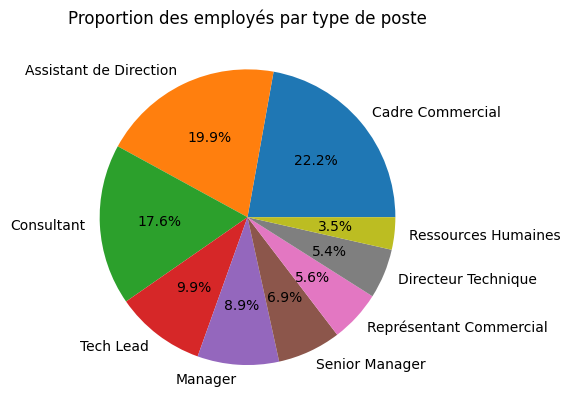

In [16]:
plt.pie(df_brut_sirh['poste'].value_counts(),labels=df_brut_sirh['poste'].unique(), autopct="%1.1f%%")
plt.title('Proportion des employés par type de poste')
plt.show()

Distribution des employés par age

([<matplotlib.axis.XTick at 0x12a86f040>,
 [Text(20, 0, '20'),
  Text(25, 0, '25'),
  Text(30, 0, '30'),
  Text(35, 0, '35'),
  Text(40, 0, '40'),
  Text(45, 0, '45'),
  Text(50, 0, '50'),
  Text(55, 0, '55'),
  Text(60, 0, '60')])

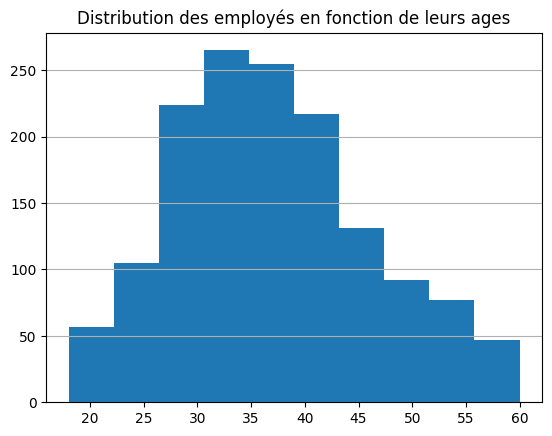

In [22]:
plt.hist(df_brut_sirh['age'])
plt.title("Distribution des employés en fonction de leurs ages")
plt.grid(axis='y')
plt.xticks([20,25,30,35,40,45,50,55,60])

Distribution salariale

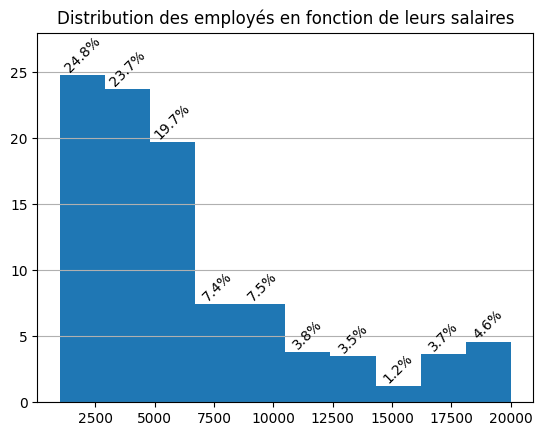

In [45]:
poids = np.ones(len(df_brut_sirh['revenu_mensuel'])) / len(df_brut_sirh['revenu_mensuel']) * 100

effectifs, bornes, barres  = plt.hist(df_brut_sirh['revenu_mensuel'], bins=10, weights=poids)
plt.title("Distribution des employés en fonction de leurs salaires")
plt.ylim(top=28)
plt.bar_label(barres,fmt="%.1f%%", rotation=45)
plt.grid(axis='y')

Distribution d'années d'experience dans le poste actuel

([<matplotlib.axis.YTick at 0x12a4ea2e0>,
 [Text(0, 25, '25'),
  Text(0, 50, '50'),
  Text(0, 75, '75'),
  Text(0, 100, '100'),
  Text(0, 200, '200'),
  Text(0, 300, '300'),
  Text(0, 400, '400'),
  Text(0, 500, '500')])

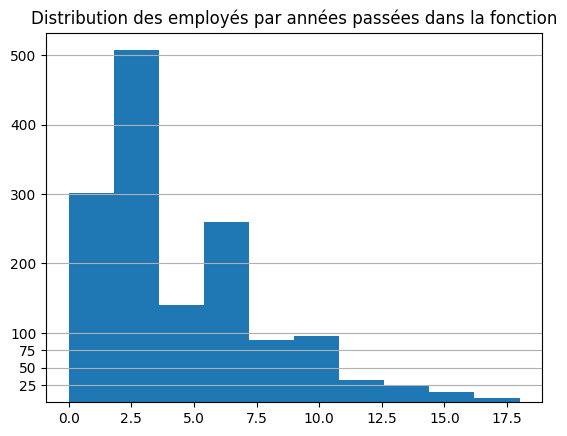

In [27]:
plt.hist(df_brut_sirh['annees_dans_le_poste_actuel'])
plt.title("Distribution des employés par années passées dans la fonction")
plt.grid(axis='y')
plt.yticks([25, 50, 75, 100,200,300,400,500])